In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("loan_approval_dataset.csv")
data.head()

data.columns = data.columns.str.strip()
data.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [3]:
data.describe(include = 'all')

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
count,4269.000000,4269.000000,4269,4269,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03,4269
unique,NaN,NaN,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,Graduate,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Approved
freq,NaN,NaN,2144,2150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2656
mean,2135.000000,2.498712,NaN,NaN,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06,NaN
std,1232.498479,1.695910,NaN,NaN,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06,NaN
min,1.000000,0.000000,NaN,NaN,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00,NaN
25%,1068.000000,1.000000,NaN,NaN,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06,NaN
50%,2135.000000,3.000000,NaN,NaN,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06,NaN
75%,3202.000000,4.000000,NaN,NaN,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06,NaN


In [4]:
print("Shape:", data.shape)

print(data.dtypes)

print(data.info())

Shape: (4269, 13)
loan_id                     int64
no_of_dependents            int64
education                     str
self_employed                 str
income_annum                int64
loan_amount                 int64
loan_term                   int64
cibil_score                 int64
residential_assets_value    int64
commercial_assets_value     int64
luxury_assets_value         int64
bank_asset_value            int64
loan_status                   str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   loan_id                   4269 non-null   int64
 1   no_of_dependents          4269 non-null   int64
 2   education                 4269 non-null   str  
 3   self_employed             4269 non-null   str  
 4   income_annum              4269 non-null   int64
 5   loan_amount               4269 non-null   int64
 6   l

array([[<Axes: title={'center': 'loan_id'}>,
        <Axes: title={'center': 'no_of_dependents'}>,
        <Axes: title={'center': 'income_annum'}>],
       [<Axes: title={'center': 'loan_amount'}>,
        <Axes: title={'center': 'loan_term'}>,
        <Axes: title={'center': 'cibil_score'}>],
       [<Axes: title={'center': 'residential_assets_value'}>,
        <Axes: title={'center': 'commercial_assets_value'}>,
        <Axes: title={'center': 'luxury_assets_value'}>],
       [<Axes: title={'center': 'bank_asset_value'}>, <Axes: >, <Axes: >]],
      dtype=object)

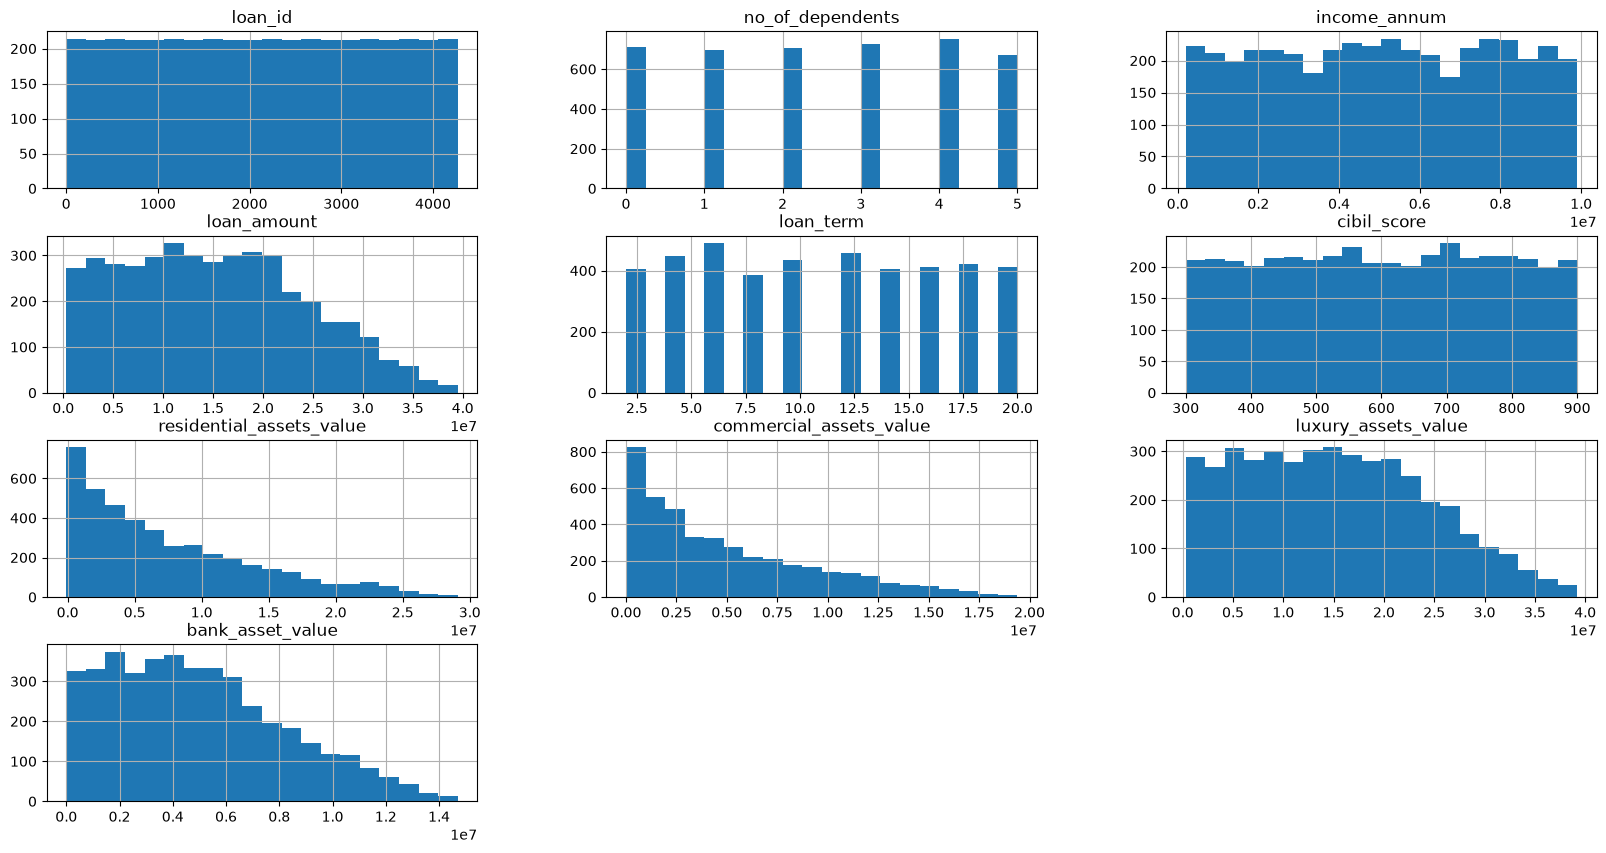

In [5]:
data.hist(figsize = (20,10), bins = 20)

In [6]:
data.isnull().sum()

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

In [7]:
num_cols = data.select_dtypes(include = np.number).columns
num_df = data.select_dtypes(include = np.number)

cat_cols = data.select_dtypes(include = ['object', 'string', 'category']).columns

In [8]:
for cols in num_cols:
    data[cols] = data[cols].fillna(value = 'mean')

In [9]:
for cols in cat_cols:
    data[cols] = data[cols].fillna(value = 'mode'[0])

<Axes: >

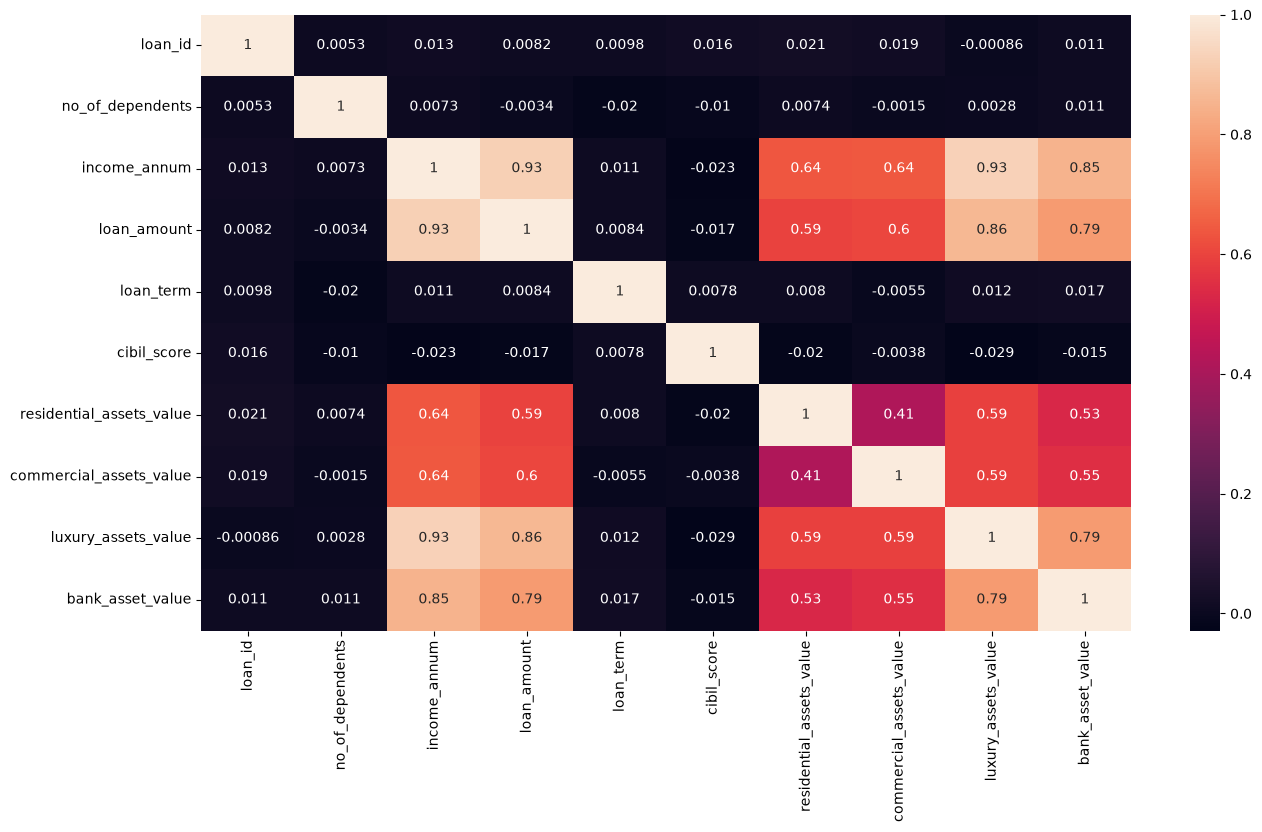

In [10]:
plt.figure(figsize=(15,8))
sns.heatmap(num_df.corr(), annot = True)

<Axes: xlabel='loan_status', ylabel='count'>

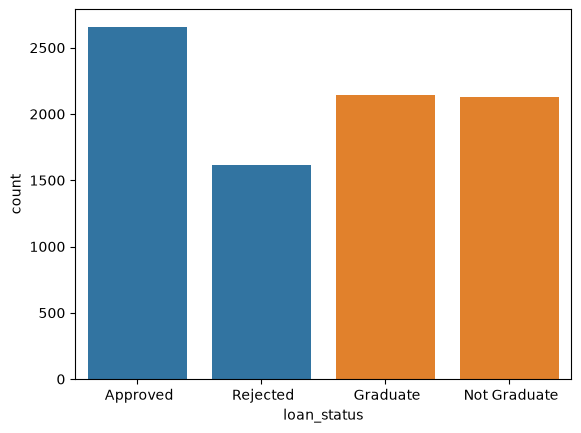

In [11]:
sns.countplot(x='loan_status' , data = data, legend=True)
sns.countplot(x='education' , data = data,legend= True)

Outlier Detection

In [12]:
for cols in num_cols:
    Q1 = data[cols].quantile(0.25)
    Q3 = data[cols].quantile(0.75)

    IQR = Q3-Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    outlier = data[(data[cols]<lower) | (data[cols] > upper)]

    print(cols , len(outlier))

loan_id 0
no_of_dependents 0
income_annum 0
loan_amount 0
loan_term 0
cibil_score 0
residential_assets_value 52
commercial_assets_value 37
luxury_assets_value 0
bank_asset_value 5


<Axes: >

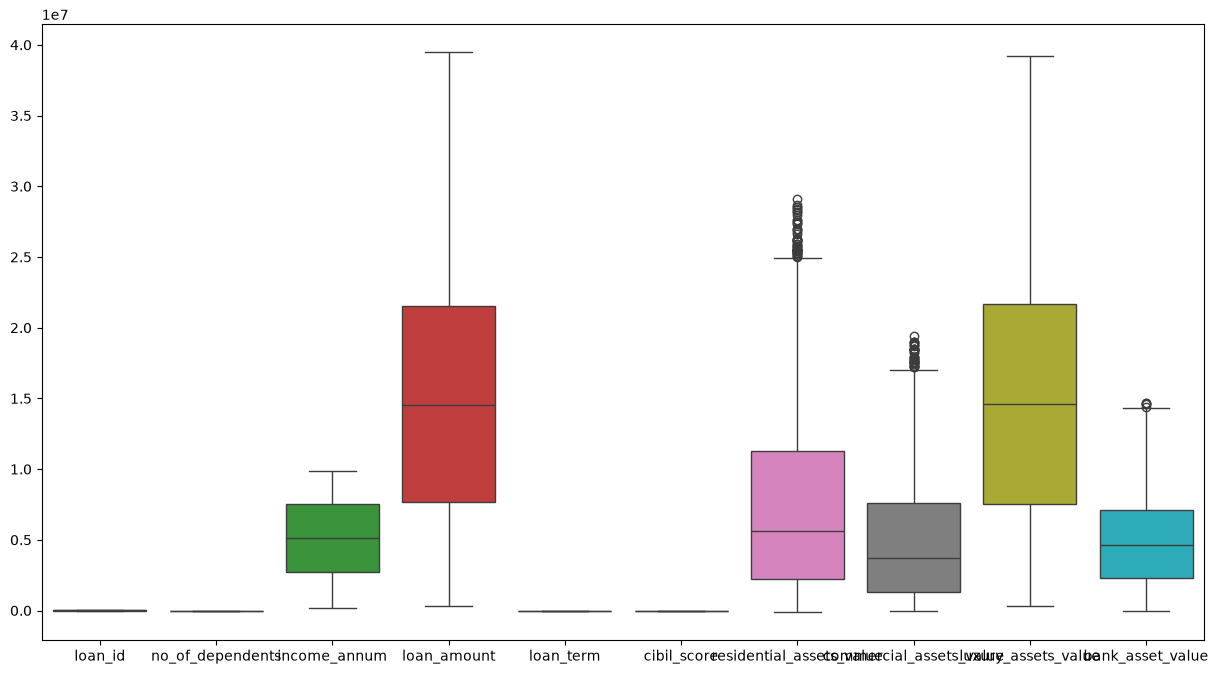

In [13]:
plt.figure(figsize=(15,8))
sns.boxplot(data = data)

In [14]:
for cols in num_cols:
    Q1 = data[cols].quantile(0.25)
    Q3 = data[cols].quantile(0.75)

    IQR = Q3-Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    data[cols] = data[cols].clip(lower,upper)

In [15]:
for cols in num_cols:
    Q1 = data[cols].quantile(0.25)
    Q3 = data[cols].quantile(0.75)

    IQR = Q3-Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    outlier = data[(data[cols]<lower) | (data[cols] > upper)]

    print(cols , len(outlier))

loan_id 0
no_of_dependents 0
income_annum 0
loan_amount 0
loan_term 0
cibil_score 0
residential_assets_value 0
commercial_assets_value 0
luxury_assets_value 0
bank_asset_value 0


<Axes: >

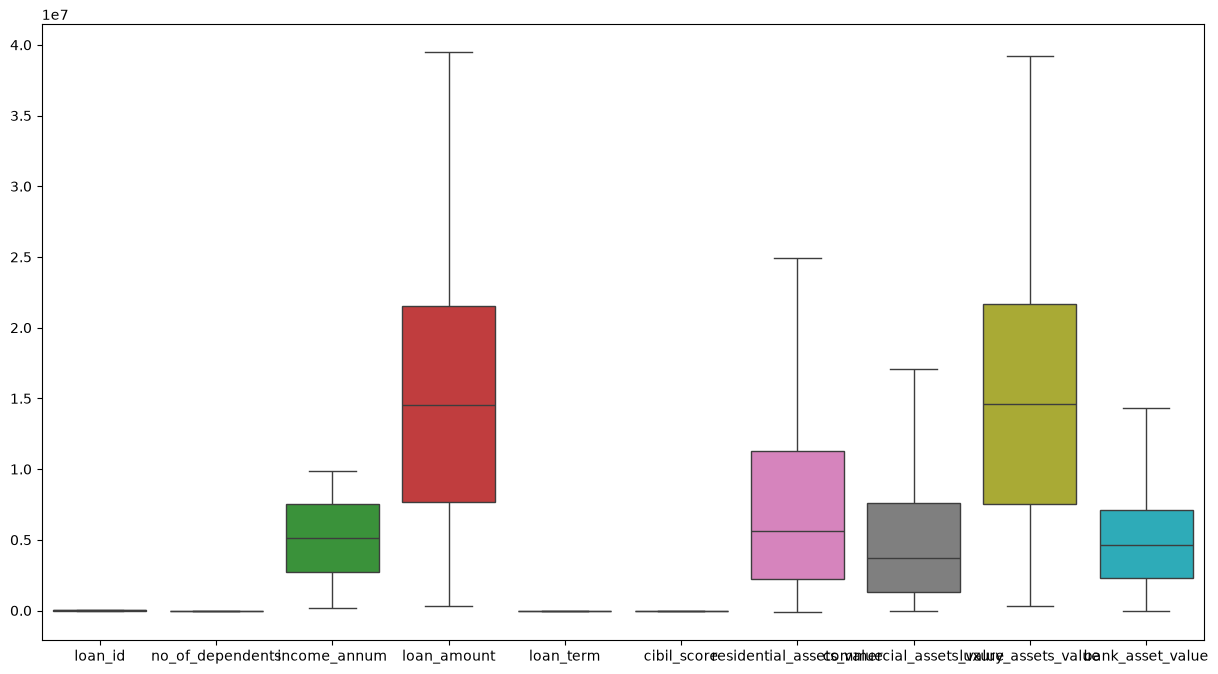

In [16]:
plt.figure(figsize=(15,8))
sns.boxplot(data = data)

In [17]:
data['loan_status'].value_counts()

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

In [18]:
target = "loan_status"

data[target] = data[target].astype(str).str.strip()

data[target] = data[target].map({
    "Approved": 1,
    "Rejected": 0,
    "1": 1,
    "0": 0
})

#data = data.dropna(subset=[target])
#data[target] = data[target].astype(int)

In [19]:
data.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17050000,22700000,8000000,1
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0


In [20]:
X = data.drop(columns=[target])
y = data[target]

In [21]:
X = pd.get_dummies(
    X,
    drop_first =True
)

In [22]:
X

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,education_ Not Graduate,self_employed_ Yes
0,1,2,9600000,29900000,12,778,2400000,17050000,22700000,8000000,False,False
1,2,0,4100000,12200000,8,417,2700000,2200000,8800000,3300000,True,True
2,3,3,9100000,29700000,20,506,7100000,4500000,33300000,12800000,False,False
3,4,3,8200000,30700000,8,467,18200000,3300000,23300000,7900000,False,False
4,5,5,9800000,24200000,20,382,12400000,8200000,29400000,5000000,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...
4264,4265,5,1000000,2300000,12,317,2800000,500000,3300000,800000,False,True
4265,4266,0,3300000,11300000,20,559,4200000,2900000,11000000,1900000,True,True
4266,4267,2,6500000,23900000,18,457,1200000,12400000,18100000,7300000,True,False
4267,4268,1,4100000,12800000,8,780,8200000,700000,14100000,5800000,True,False


In [23]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, random_state = 42)

In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [25]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

model = DecisionTreeClassifier()

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

ImportError: DLL load failed while importing _libsvm: An Application Control policy has blocked this file.

In [ ]:
#metrics
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix
print("Accuracy", accuracy_score(y_test, y_pred))
print("Recall Score", recall_score(y_test, y_pred))

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

model2 = KNeighborsClassifier(n_neighbors = 3)

model2.fit(X_train_scaled, y_train)
y_pred2 = model2.predict(X_test_scaled)

In [ ]:
print("Accuracy", accuracy_score(y_test, y_pred2))
print("Recall Score", recall_score(y_test, y_pred2))

In [ ]:
from sklearn.naive_bayes import GaussianNB

model3 = GaussianNB()

model3.fit(X_train_scaled, y_train)

y_pred3 = model3.predict(X_test_scaled)

In [ ]:
print("Accuracy", accuracy_score(y_test, y_pred3))
print("Recall Score", recall_score(y_test, y_pred3))

In [ ]:
from sklearn.svm import SVC
model4 = SVC(random_state=42)

model4.fit(X_train_scaled, y_train)

y_pred4 = model4.predict(X_test_scaled)

In [ ]:
print("Accuracy", accuracy_score(y_test, y_pred4))
print("Recall Score", recall_score(y_test, y_pred4))